In [36]:
import os, glob, time
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(DEVICE)

cuda


In [37]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE       = "/content/drive/MyDrive"
SCENES_ROOT = f"{DRIVE}/Forest batch 1"          #shortcut, read only
DATA_ROOT   = f"{DRIVE}/drone-val"                       #validation, not test
OUT         = f"{DRIVE}/outputs_val/dehazenet_v8"
CKPT        = f"{DRIVE}/checkpoints/dehazenet_v8.pth"

HAZY, CLEAR = "visible_haze", "visible_clear"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


parameter

In [38]:
#training data
TRAIN_STEP = 5            #every 5th frame, ~400 pairs
LONG_SIDE = 512           #resize before caching in RAM
CROP = 256

#training
EPOCHS = 30
BATCH = 16
LR = 1e-3

#physics, same as DCP
A_PATCH = 15              #dark channel patch for A
A_TOP = 0.001             #brightest 0.1% of the dark channel
T_MIN = 0.1

#t refinement at inference (guided filter, as in the paper)
GF_RADIUS = 60
GF_EPS = 1e-3

training data

In [39]:
#training data: 6 train scenes (08 overcast is held out for validation), cached at long side 512
data = np.load(f"{DRIVE}/train_cache_6scenes_step5_512.npz")
pairs = list(zip(data["hazy"], data["gt"]))
print(len(pairs), "pairs")


class PairDataset(torch.utils.data.Dataset):
    #random crop + horizontal flip
    def __len__(self):
        return len(pairs)

    def __getitem__(self, i):
        hazy, gt = pairs[i]
        y = np.random.randint(0, hazy.shape[0] - CROP + 1)
        x = np.random.randint(0, hazy.shape[1] - CROP + 1)
        hazy, gt = hazy[y:y + CROP, x:x + CROP], gt[y:y + CROP, x:x + CROP]
        if np.random.rand() < 0.5:
            hazy, gt = hazy[:, ::-1], gt[:, ::-1]
        to_t = lambda a: torch.from_numpy(a.copy()).permute(2, 0, 1).float() / 255
        return to_t(hazy), to_t(gt)


loader = torch.utils.data.DataLoader(PairDataset(), batch_size=BATCH, shuffle=True, num_workers=2, drop_last=True)

366 pairs


model

In [40]:
class DehazeNet(nn.Module):
    #v8: larger t branch (32 ch, dilated 1/2/4/8/16, receptive field ~65 px at long side 512); A branch unchanged
    def __init__(self, c=32):
        super().__init__()
        layers = [nn.Conv2d(3, c, 3, padding=1), nn.ReLU()]
        for d in (2, 4, 8, 16):
            layers += [nn.Conv2d(c, c, 3, padding=d, dilation=d), nn.ReLU()]
        layers += [nn.Conv2d(c, 1, 3, padding=1)]
        self.t_body = nn.Sequential(*layers)
        self.a_head = nn.Sequential(
            nn.Conv2d(3, 16, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(32, 3), nn.Sigmoid())                       #A in [0, 1], (B, 3)

    def transmission(self, x):
        return torch.sigmoid(self.t_body(x))                       #smooth, gradient never exactly zero

    def forward(self, x):
        return self.transmission(x), self.a_head(x)


def recover(I, t, A):
    A = A[:, :, None, None]
    return ((I - A) / t.clamp(min=T_MIN) + A).clamp(0, 1)          #invert I = J*t + A*(1-t)


net = DehazeNet().to(DEVICE)
nn.init.constant_(net.a_head[-2].bias, 2.0)                        #A starts near sigmoid(2) = 0.88, like a bright airlight
nn.init.zeros_(net.t_body[-1].weight)                              #t starts at sigmoid(0) = 0.5 everywhere
nn.init.zeros_(net.t_body[-1].bias)                                #no saturation at the start
print(f"{sum(p.numel() for p in net.parameters())} params")

43364 params


train

In [41]:
opt = torch.optim.Adam(net.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)

for epoch in range(EPOCHS):
    net.train()
    total = 0
    for hazy, gt in loader:
        hazy, gt = hazy.to(DEVICE), gt.to(DEVICE)
        t, A = net(hazy)
        J = recover(hazy, t, A)
        loss = F.l1_loss(J, gt)
        opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item()
    sched.step()
    print(f"epoch {epoch + 1}/{EPOCHS} | L1 {total / len(loader):.4f}")

os.makedirs(os.path.dirname(CKPT), exist_ok=True)
torch.save(net.state_dict(), CKPT)

epoch 1/30 | L1 0.1522
epoch 2/30 | L1 0.0897
epoch 3/30 | L1 0.0895
epoch 4/30 | L1 0.0893
epoch 5/30 | L1 0.0901
epoch 6/30 | L1 0.0885
epoch 7/30 | L1 0.0877
epoch 8/30 | L1 0.0880
epoch 9/30 | L1 0.0851
epoch 10/30 | L1 0.0752
epoch 11/30 | L1 0.0687
epoch 12/30 | L1 0.0668
epoch 13/30 | L1 0.0664
epoch 14/30 | L1 0.0660
epoch 15/30 | L1 0.0661
epoch 16/30 | L1 0.0648
epoch 17/30 | L1 0.0655
epoch 18/30 | L1 0.0652
epoch 19/30 | L1 0.0653
epoch 20/30 | L1 0.0644
epoch 21/30 | L1 0.0646
epoch 22/30 | L1 0.0641
epoch 23/30 | L1 0.0637
epoch 24/30 | L1 0.0645
epoch 25/30 | L1 0.0639
epoch 26/30 | L1 0.0640
epoch 27/30 | L1 0.0642
epoch 28/30 | L1 0.0640
epoch 29/30 | L1 0.0642
epoch 30/30 | L1 0.0640


In [42]:
#diagnose: is t saturated at 1?
hz, _ = next(iter(loader))
with torch.no_grad():
    t, A = net(hz.to(DEVICE))
    logit = net.t_body(hz.to(DEVICE))
print("t   min/mean/max:", t.min().item(), t.mean().item(), t.max().item())
print("logit min/max:", logit.min().item(), logit.max().item())
print("A:", A[:2])
!ls -l --time-style=+%H:%M "/content/drive/MyDrive/outputs_val/dehazenet_v8" | head -3

t   min/mean/max: 0.6089355945587158 0.8699172735214233 0.973311185836792
logit min/max: 0.44284045696258545 3.5964572429656982
A: tensor([[0.4603, 0.5220, 0.9291],
        [0.5111, 0.5647, 0.9257]], device='cuda:0')
ls: cannot access '/content/drive/MyDrive/outputs_val/dehazenet_v8': No such file or directory


inference

In [43]:
def guided_filter(guide, src, r=GF_RADIUS, eps=GF_EPS):
    #edge-preserving smoothing of src, following the edges of guide (He et al., 2010)
    box = lambda x: cv2.boxFilter(x, -1, (2 * r + 1, 2 * r + 1))
    mean_I, mean_p = box(guide), box(src)
    a = (box(guide * src) - mean_I * mean_p) / (box(guide * guide) - mean_I * mean_I + eps)
    b = mean_p - a * mean_I
    return box(a) * guide + box(b)


@torch.no_grad()
def dehaze_full(rgb):
    #t and A estimated at the training scale (long side LONG_SIDE), t upsampled with the guided filter
    net.eval()
    I = torch.from_numpy(rgb.copy()).permute(2, 0, 1)[None].float().div(255).to(DEVICE)
    H, W = I.shape[2:]
    t_small, A = net(F.interpolate(I, scale_factor=LONG_SIDE / max(H, W), mode='bilinear'))
    t = F.interpolate(t_small, size=(H, W), mode='bilinear')[0, 0].cpu().numpy()
    t = guided_filter(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255, t)
    J = recover(I, torch.from_numpy(t).to(DEVICE)[None, None], A)
    return (J[0].permute(1, 2, 0).cpu().numpy() * 255 + 0.5).astype(np.uint8), t


def dehaze(hazy):
    #hazy: PIL RGB image -> uint8 RGB array
    return dehaze_full(np.asarray(hazy))[0]

preview a single image

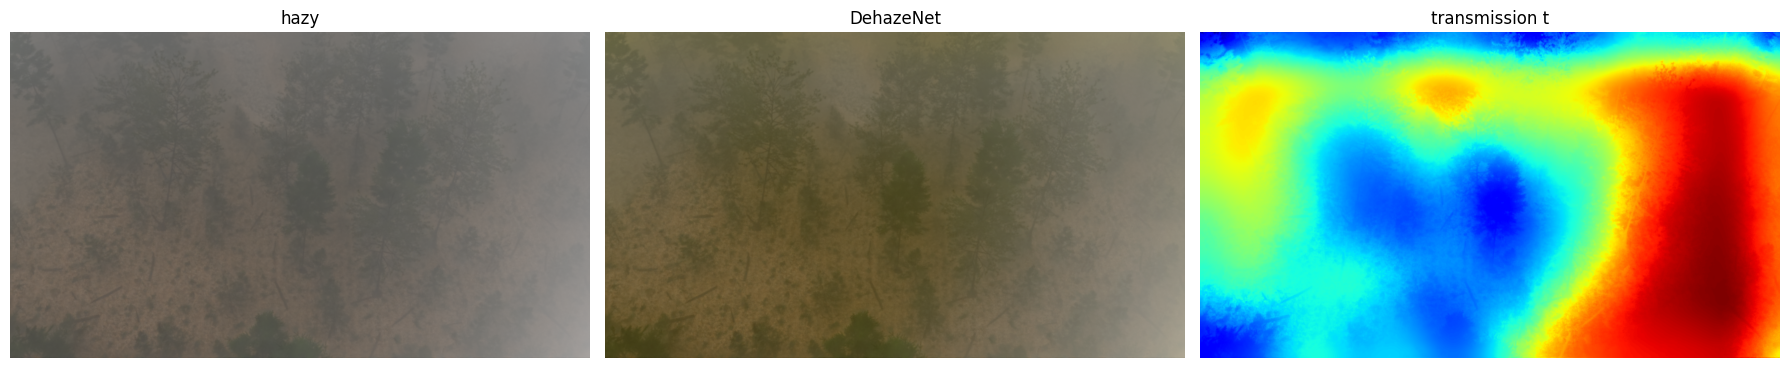

In [44]:
hazy_paths = sorted(glob.glob(f"{DATA_ROOT}/hazy/*"))
os.makedirs(OUT, exist_ok=True)

hazy = np.asarray(Image.open(hazy_paths[0]).convert('RGB'))
J, t = dehaze_full(hazy)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, im, title, cmap in zip(ax, [hazy, J, t], ['hazy', 'DehazeNet', 'transmission t'], [None, None, 'jet']):
    a.imshow(im, cmap=cmap); a.set_title(title); a.axis('off')
plt.tight_layout(); plt.show()

run over the test set

In [45]:
for p in hazy_paths:
    hazy = Image.open(p).convert('RGB')
    t0 = time.time()
    pred = dehaze(hazy)
    dt = time.time() - t0
    Image.fromarray(pred).save(f"{OUT}/{os.path.basename(p)}")
    print(f"{os.path.basename(p)} | {hazy.size[0]}x{hazy.size[1]} | {dt:.2f}s")

08_overcast_hover-southwest_0001.png | 1280x720 | 0.06s
08_overcast_hover-southwest_0015.png | 1280x720 | 0.05s
08_overcast_hover-southwest_0030.png | 1280x720 | 0.06s
08_overcast_hover-southwest_0045.png | 1280x720 | 0.05s
08_overcast_hover-southwest_0060.png | 1280x720 | 0.06s
08_overcast_hover-southwest_0075.png | 1280x720 | 0.05s
08_overcast_hover-southwest_0090.png | 1280x720 | 0.06s
08_overcast_hover-southwest_0105.png | 1280x720 | 0.05s
08_overcast_hover-southwest_0120.png | 1280x720 | 0.06s
08_overcast_hover-southwest_0135.png | 1280x720 | 0.05s
08_overcast_hover-southwest_0150.png | 1280x720 | 0.06s
08_overcast_hover-southwest_0165.png | 1280x720 | 0.06s
08_overcast_hover-southwest_0180.png | 1280x720 | 0.06s
08_overcast_hover-southwest_0195.png | 1280x720 | 0.05s
08_overcast_hover-southwest_0210.png | 1280x720 | 0.06s


evaluate

In [46]:
!pip install -q pyiqa
!rm -rf /content/vx
!git clone -q --depth 1 https://github.com/fahimrayhan/vidhance-extendview.git /content/vx

import sys
from pathlib import Path
sys.path.insert(0, "/content/vx/dehazing")
from evaluation import evaluate

In [47]:
import pandas as pd
OUTPUTS = Path(f"{DRIVE}/outputs_val")
NEW = ["dehazenet_v8"]
ALL = OUTPUTS / "per_image_val.csv"

per_image_new, _ = evaluate(DATA_ROOT, {m: str(OUTPUTS / m) for m in NEW})
old = pd.read_csv(ALL) if ALL.exists() else per_image_new.iloc[0:0]
keep_hazy = per_image_new if not (old.method == "hazy").any() else per_image_new[per_image_new.method != "hazy"]
per_image = pd.concat([old[~old.method.isin(NEW)], keep_hazy])
per_image.to_csv(ALL, index=False)

summary = per_image.groupby("method", sort=False).mean(numeric_only=True)
summary.to_csv(OUTPUTS / "summary_val.csv")
summary

[1/15] 08_overcast_hover-southwest_0001.png
[2/15] 08_overcast_hover-southwest_0015.png
[3/15] 08_overcast_hover-southwest_0030.png
[4/15] 08_overcast_hover-southwest_0045.png
[5/15] 08_overcast_hover-southwest_0060.png
[6/15] 08_overcast_hover-southwest_0075.png
[7/15] 08_overcast_hover-southwest_0090.png
[8/15] 08_overcast_hover-southwest_0105.png
[9/15] 08_overcast_hover-southwest_0120.png
[10/15] 08_overcast_hover-southwest_0135.png
[11/15] 08_overcast_hover-southwest_0150.png
[12/15] 08_overcast_hover-southwest_0165.png
[13/15] 08_overcast_hover-southwest_0180.png
[14/15] 08_overcast_hover-southwest_0195.png
[15/15] 08_overcast_hover-southwest_0210.png


,psnr,ssim,ciede2000,lpips,niqe,brisque,e,r,sigma
method,,,,,,,,,
hazy,16.628117,0.484373,14.095817,0.662183,5.232528,29.706108,0.000000,1.000000,0.0
dehazenet_v4r,18.670550,0.514562,10.504603,0.620219,5.034739,27.849915,1.600775,1.125655,0.0
cap,19.711093,0.551034,12.100555,0.585522,4.714936,25.689669,11.603946,1.414628,0.0
dehazenet_v6r,17.159221,0.520716,11.233822,0.588252,5.045262,29.388139,4.525737,1.376291,0.0
dehazenet_v8,18.707902,0.526059,10.008022,0.615276,4.881820,26.422335,4.347680,1.242560,0.0
